###Google Drive Connect

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


###Complete Project Folder Structure

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/ArteryAI")

folders = [
    "Milestone-1",
    "Milestone-1/outputs",
    "Milestone-2",
    "Milestone-2/outputs/masks",
    "Milestone-2/outputs/centerlines",
    "Milestone-2/outputs/vessel_analysis",
    "Milestone-3",
    "Milestone-3/outputs/stenosis",
    "Milestone-3/outputs/gradcam",
    "Milestone-3/outputs/severity",
    "Milestone-4",
    "Milestone-4/reports",
    "Milestone-4/tests",
    "data/raw",
    "data/processed",
    "models/checkpoints",
    "src",
    "docs",
    "logs"
]

for folder in folders:
    (ROOT / folder).mkdir(
        parents=True, exist_ok=True
    )

print("Project initialized successfully!")
print("Project path:", ROOT)

for folder in sorted(ROOT.iterdir()):
    print(folder.name)

Project initialized successfully!
Project path: /content/drive/MyDrive/ArteryAI
Milestone-1
Milestone-2
Milestone-3
Milestone-4
data
docs
logs
models
src


# Artery Segmentation and Stenosis Detection Using Advanced Deep Learning Techniques

## Project Objectives
- Automatically segment coronary arteries from medical images.
- Extract vessel boundaries, centerlines and branching structures.
- Estimate vessel diameter, length and tortuosity.
- Detect and localize suspected stenotic regions.
- Estimate percentage arterial narrowing and severity.
- Compare baseline and advanced deep learning architectures.
- Implement explainable AI using Grad-CAM and attention maps.
- Evaluate segmentation and detection performance.
- Generate automated PDF, CSV and JSON reports.

## Selected Imaging Modality
2D X-ray Coronary Angiography.

## Selected Dataset
ARCADE — Automatic Region-based Coronary Artery Disease Diagnostics Using X-Ray Angiography Images.

## Project Workflow
Dataset Acquisition → EDA → Preprocessing → Artery Segmentation → Vessel Analysis → Stenosis Detection → Severity Assessment → Explainable AI → Evaluation → Reporting.

## Disclaimer
This system is intended for research and AI-assisted analysis, not standalone clinical diagnosis.

###Install Required Libraries

In [ ]:
!pip -q install datasets huggingface_hub \
    segmentation-models-pytorch \
    reportlab grad-cam graphviz

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [ ]:
import torch
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import random
import json
import os
import time

from pathlib import Path

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


###Shared Project Configuration

In [ ]:
%%writefile /content/drive/MyDrive/ArteryAI/src/config.py

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/ArteryAI")

DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

MODEL_DIR = ROOT / "models/checkpoints"

M1 = ROOT / "Milestone-1"
M2 = ROOT / "Milestone-2"
M3 = ROOT / "Milestone-3"
M4 = ROOT / "Milestone-4"

SEED = 42

QUICK_MODE = True

IMAGE_SIZE = 256 if QUICK_MODE else 512

TRAIN_LIMIT = 150 if QUICK_MODE else None
VAL_LIMIT = 40 if QUICK_MODE else None
TEST_LIMIT = 40 if QUICK_MODE else None

BATCH_SIZE = 8
EPOCHS = 3 if QUICK_MODE else 50
LEARNING_RATE = 0.001

DATASET_NAME = "ARCADE"
MODALITY = "X-ray Coronary Angiography"

Writing /content/drive/MyDrive/ArteryAI/src/config.py


###Generate System Architecture Diagram

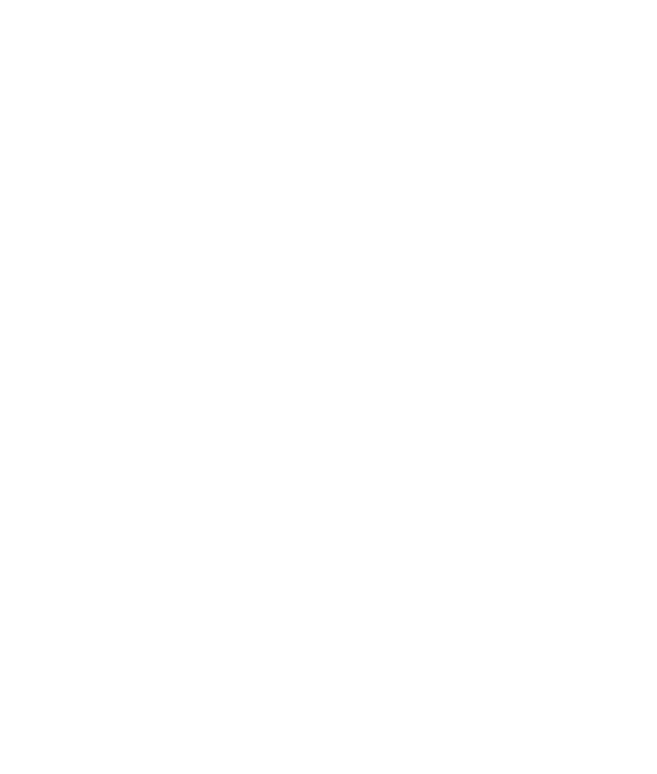

In [ ]:
from graphviz import Digraph
from IPython.display import display

dot = Digraph("ArteryAI", format="png")

dot.attr(
    rankdir="TB",
    bgcolor="white",
    dpi="180"
)

dot.attr(
    "node",
    shape="box",
    style="rounded,filled",
    fillcolor="#E8F1FF",
    fontname="Arial"
)

dot.node("A", "Medical Image Dataset\nARCADE")
dot.node("B", "Image Validation & Preprocessing")

dot.node("C1", "U-Net\nBaseline Model")
dot.node("C2", "Attention U-Net\nAdvanced Model")

dot.node("D", "Segmentation Mask")
dot.node("E", "Post-processing & Vessel Analysis")
dot.node("F", "Centerline, Branches & Diameter")
dot.node("G", "Stenosis Detection Engine")
dot.node("H", "Severity Assessment")
dot.node("I", "Explainable AI\nGrad-CAM / Attention Maps")
dot.node("J", "Model Evaluation & Comparison")
dot.node("K", "Analysis Dashboard")
dot.node("L", "PDF / CSV / JSON Reports")

dot.node("M", "PostgreSQL Database\nFuture Integration",
         fillcolor="#EEEEEE")

dot.node("N", "FastAPI Backend\nFuture Integration",
         fillcolor="#EEEEEE")

dot.node("O", "React Frontend\nFuture Integration",
         fillcolor="#EEEEEE")

dot.edges([
    ("A", "B"),
    ("B", "C1"),
    ("B", "C2"),
    ("C1", "D"),
    ("C2", "D"),
    ("D", "E"),
    ("E", "F"),
    ("F", "G"),
    ("G", "H"),
    ("G", "I"),
    ("H", "K"),
    ("I", "K"),
    ("C1", "J"),
    ("C2", "J"),
    ("G", "J"),
    ("J", "K"),
    ("K", "L")
])

dot.edge("K", "N", style="dashed")
dot.edge("N", "M", style="dashed")
dot.edge("N", "O", style="dashed")

dot.render(
    str(ROOT / "Milestone-1/system_architecture"),
    cleanup=True
)

display(dot)

###Database Schema Design

In [ ]:
%%writefile /content/drive/MyDrive/ArteryAI/Milestone-1/database_schema.sql

CREATE TABLE users (
    user_id SERIAL PRIMARY KEY,
    name VARCHAR(100) NOT NULL,
    email VARCHAR(150) UNIQUE NOT NULL,
    password_hash TEXT NOT NULL,
    role VARCHAR(30) NOT NULL,
    created_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP
);

CREATE TABLE patients (
    patient_id SERIAL PRIMARY KEY,
    anonymous_code VARCHAR(100) UNIQUE NOT NULL,
    age INT,
    gender VARCHAR(20),
    medical_history TEXT,
    risk_factors TEXT,
    clinical_notes TEXT
);

CREATE TABLE cases (
    case_id SERIAL PRIMARY KEY,
    patient_id INT REFERENCES patients(patient_id),
    user_id INT REFERENCES users(user_id),
    modality VARCHAR(100),
    anatomical_region VARCHAR(100),
    scan_date DATE,
    status VARCHAR(30),
    created_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP
);

CREATE TABLE medical_images (
    image_id SERIAL PRIMARY KEY,
    case_id INT REFERENCES cases(case_id),
    file_path TEXT NOT NULL,
    image_format VARCHAR(20),
    width INT,
    height INT,
    pixel_spacing_x FLOAT,
    pixel_spacing_y FLOAT
);

CREATE TABLE models (
    model_id SERIAL PRIMARY KEY,
    model_name VARCHAR(100),
    version VARCHAR(30),
    task VARCHAR(50),
    checkpoint_path TEXT,
    dataset_version VARCHAR(100),
    metrics JSONB,
    created_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP
);

CREATE TABLE analyses (
    analysis_id SERIAL PRIMARY KEY,
    image_id INT REFERENCES medical_images(image_id),
    model_id INT REFERENCES models(model_id),
    inference_time_ms FLOAT,
    status VARCHAR(30),
    analysis_date TIMESTAMP DEFAULT CURRENT_TIMESTAMP
);

CREATE TABLE segmentations (
    segmentation_id SERIAL PRIMARY KEY,
    analysis_id INT REFERENCES analyses(analysis_id),
    mask_path TEXT,
    overlay_path TEXT,
    vessel_count INT,
    metrics JSONB
);

CREATE TABLE vessel_measurements (
    measurement_id SERIAL PRIMARY KEY,
    segmentation_id INT REFERENCES
        segmentations(segmentation_id),
    branch_id INT,
    diameter FLOAT,
    vessel_length FLOAT,
    cross_sectional_area FLOAT,
    tortuosity FLOAT,
    branching_points INT,
    measurement_unit VARCHAR(20),
    centerline_path TEXT
);

CREATE TABLE stenosis_results (
    stenosis_id SERIAL PRIMARY KEY,
    analysis_id INT REFERENCES analyses(analysis_id),
    location_x FLOAT,
    location_y FLOAT,
    bounding_box JSONB,
    reference_diameter FLOAT,
    minimum_diameter FLOAT,
    narrowing_percentage FLOAT,
    severity VARCHAR(50),
    confidence FLOAT
);

CREATE TABLE explainability_results (
    explanation_id SERIAL PRIMARY KEY,
    analysis_id INT REFERENCES analyses(analysis_id),
    method VARCHAR(50),
    heatmap_path TEXT
);

CREATE TABLE reports (
    report_id SERIAL PRIMARY KEY,
    analysis_id INT REFERENCES analyses(analysis_id),
    pdf_path TEXT,
    csv_path TEXT,
    json_path TEXT,
    created_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP
);

CREATE TABLE alerts (
    alert_id SERIAL PRIMARY KEY,
    analysis_id INT REFERENCES analyses(analysis_id),
    alert_type VARCHAR(100),
    alert_level VARCHAR(30),
    message TEXT,
    created_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP
);

CREATE TABLE audit_logs (
    log_id SERIAL PRIMARY KEY,
    user_id INT REFERENCES users(user_id),
    action TEXT,
    timestamp TIMESTAMP DEFAULT CURRENT_TIMESTAMP
);

Writing /content/drive/MyDrive/ArteryAI/Milestone-1/database_schema.sql


###Generate Project README

In [ ]:
%%writefile /content/drive/MyDrive/ArteryAI/Milestone-1/README.md

# Milestone 1: Project Initialization and Dataset Setup

## Project
Artery Segmentation and Stenosis Detection
Using Advanced Deep Learning Techniques.

## Imaging Modality
2D X-ray Coronary Angiography.

## Selected Dataset
ARCADE

Official source:
https://zenodo.org/records/10390295

## Technology Stack
- Python
- PyTorch
- OpenCV
- NumPy
- Pandas
- Matplotlib
- PostgreSQL (planned)

## Implementation Status
- Project objectives: Defined
- Project workflow: Defined
- Imaging modality: Selected
- Dataset: Selected
- Dataset download: Pending
- Exploratory data analysis: Pending
- System architecture: Designed
- Database schema: Designed
- Image preprocessing: Pending

## Limitations
The initial implementation uses 2D angiography.
Clinical validation and physical vessel calibration
are not yet completed.

## Disclaimer
This project is intended for research purposes
and not standalone clinical diagnosis.

Writing /content/drive/MyDrive/ArteryAI/Milestone-1/README.md
